In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

In [ ]:
df=pd.read_csv("Student Social Media And Mental Health Impact.csv",delimiter=",")

In [ ]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [ ]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [ ]:
df["Academic_Level"].unique()

array(['Undergraduate', 'Graduate', 'High School'], dtype=object)

<Axes: xlabel='Academic_Level', ylabel='Mental_Health_Score'>

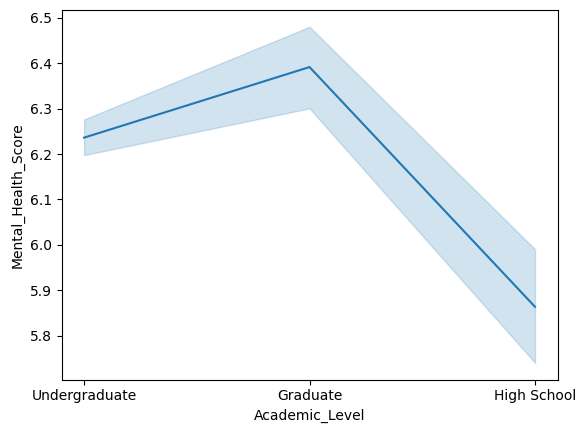

In [ ]:
sns.lineplot(x="Academic_Level",y="Mental_Health_Score",data=df)

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

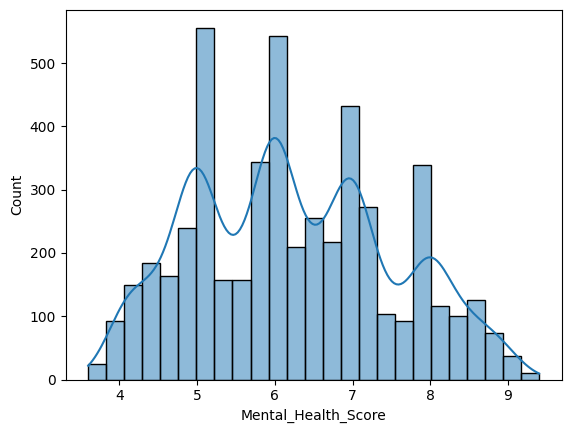

In [ ]:
sns.histplot(x='Mental_Health_Score',data=df,kde=True)

<Axes: >

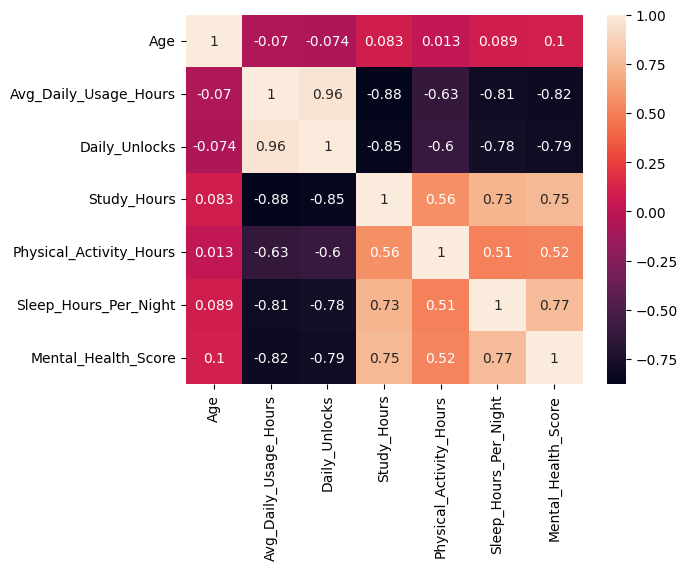

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [ ]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751400,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.667274,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [ ]:
df["Physical_Activity_Hours"]=df['Physical_Activity_Hours'].clip(lower=0)

In [ ]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [ ]:
top_countries=df['Country'].value_counts().head(10).index.to_list()
print(top_countries)


['Other', 'India', 'USA', 'Canada', 'Australia', 'UK', 'Germany', 'Mexico', 'Turkey', 'France']


In [ ]:
def grouped_countries(country):
  if country in top_countries:
    return country
  else:
    return "Other"

In [ ]:
df["grouped_countries"]=df["Country"].apply(grouped_countries)

In [ ]:
df['grouped_countries'].value_counts()

,count
grouped_countries,
Other,3232
India,389
USA,355
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


In [ ]:
numeric_cols=df.select_dtypes(include='number')
numeric_cols.skew()

,0
Age,0.155325
Avg_Daily_Usage_Hours,0.005606
Daily_Unlocks,0.002351
Study_Hours,0.435819
Physical_Activity_Hours,0.052632
Sleep_Hours_Per_Night,0.124050
Mental_Health_Score,0.206567


In [ ]:
numbers=df.select_dtypes(include='number')
q1=numbers.quantile(0.25)
q3=numbers.quantile(0.75)
IQR=q3-q1

upper_bound=q3+1.5*IQR
lower_bound=q1-1.5*IQR


outliers= (numbers > upper_bound) | (numbers < lower_bound)
print(outliers.sum())


Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


In [ ]:
df.drop_duplicates()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,18,Female,Other,High School,YouTube,Education,1.9,89,6.1,2.2,7.9,Low,7.9
4996,18,Female,Other,High School,YouTube,Education,6.6,216,2.3,1.8,6.0,Very High,4.7
4997,19,Female,India,Undergraduate,LinkedIn,Education,3.8,151,5.4,1.4,7.5,Medium,7.0
4998,18,Male,Other,High School,Instagram,Entertainment,3.8,119,4.0,1.5,6.4,Medium,6.7


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [ ]:
from sklearn.model_selection import train_test_split

skew_col=['Study_Hours']

order_col=["Stress_Level"]

normal_col=["Age",'Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night','Physical_Activity_Hours','Daily_Unlocks']

categorical_col=['Gender','Country','Academic_Level','Most_Used_Platform','Purpose_Of_Use']

feature=skew_col + order_col + normal_col + categorical_col
target="Mental_Health_Score"

x=df[feature]
y=df[target]

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)





In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder,OrdinalEncoder,FunctionTransformer
from sklearn.compose import ColumnTransformer

skew_pipeline=Pipeline(steps=[("skewline",FunctionTransformer(np.log1p)),("standard scalar",StandardScaler())])
order_pipeline=Pipeline(steps=[("order",OrdinalEncoder(categories=[['Low','Medium','High','Very High']]))])

number_pipeline=Pipeline(steps=[("standard scalar",StandardScaler())])

categorical_pipeline=Pipeline(steps=[("one hot",OneHotEncoder(handle_unknown="ignore"))])


preprocessor=ColumnTransformer(transformers=[("skew",skew_pipeline,skew_col),
                                           ("order",order_pipeline,order_col),
                                           ("number",number_pipeline,normal_col),
                                           ("categorical",categorical_pipeline,categorical_col)])



In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,r2_score


lr_pipeline=Pipeline(steps=[("preprocessor",preprocessor),("linear regression",LinearRegression())])
rf_pipeline=Pipeline(steps=[("preprocessor",preprocessor),("random forest",RandomForestRegressor())])

lr_pipeline.fit(x_train,y_train)
rf_pipeline.fit(x_train,y_train)

lr_pred=lr_pipeline.predict(x_test)
rf_pred=rf_pipeline.predict(x_test)
lr_pred_training_pipeline=lr_pipeline.predict(x_train)
lr_pred_trainingr2=r2_score(y_train,lr_pred_training_pipeline)


rf_pred_training_pipeline=rf_pipeline.predict(x_train)
rf_pred_trainingr2=r2_score(y_train,rf_pred_training_pipeline)


lr_r2=r2_score(y_test,lr_pred)
rf_r2=r2_score(y_test,rf_pred)

lr_mse=mean_squared_error(y_test,lr_pred)
rf_mse=mean_squared_error(y_test,rf_pred)


print("LR is ",lr_r2)
print("RF is ",rf_r2)

print("LR MSE is ",lr_mse)
print("RF MSE is ",rf_mse)






LR is  0.7927961162557874
RF is  0.9151877712575247
LR MSE is  0.35931742660977734
RF MSE is  0.14707500277555574


In [19]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'random forest__n_estimators'       : [100,200,300],
    'random forest__max_depth'         : [5,10,15],
    'random forest__min_samples_split' : [2,5,10],
    'random forest__min_samples_leaf'  : [1,2,4]
}

random=RandomizedSearchCV(estimator=rf_pipeline,param_distributions=param_grid,cv=3,n_iter=5,scoring='r2',n_jobs=-1)
random.fit(x_train,y_train)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('skew',
                                                                               Pipeline(steps=[('skewline',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('standard '
                                                                                                'scalar',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('order',
                                                                               Pipeline(steps=[('order',
                                                                                                OrdinalEncoder(categories=[['Low',
                                                                                                                            'Medium',
                                                                                                                            'High',
                                                                                                                            'Very '
                                                                                                                            'High']]))]),
                                                                               ['Stress_Level...
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['Gender',
                                                                                'Country',
                                                                                'Academic_Level',
                                                                                'Most_Used_Platform',
                                                                                'Purpose_Of_Use'])])),
                                             ('random forest',
                                              RandomForestRegressor())]),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'random forest__max_depth': [5, 10, 15],
                                        'random forest__min_samples_leaf': [1,
                                                                            2,
                                                                            4],
                                        'random forest__min_samples_split': [2,
                                                                             5,
                                                                             10],
                                        'random forest__n_estimators': [100,
                                                                        200,
                                                                        300]},
                   scoring='r2')

In [20]:
random.best_params_

{'random forest__n_estimators': 200,
 'random forest__min_samples_split': 2,
 'random forest__min_samples_leaf': 1,
 'random forest__max_depth': 10}

In [21]:
random.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew',
                                                  Pipeline(steps=[('skewline',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('standard '
                                                                   'scalar',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('order',
                                                  Pipeline(steps=[('order',
                                                                   OrdinalEncoder(categories=[['Low',
                                                                                               'Medium',
                                                                                               'High',
                                                                                               'Very '
                                                                                               'High']]))]),
                                                  ['Stress_Level']),
                                                 ('number',
                                                  Pipeline(steps=[('st...
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Sleep_Hours_Per_Night',
                                                   'Physical_Activity_Hours',
                                                   'Daily_Unlocks']),
                                                 ('categorical',
                                                  Pipeline(steps=[('one hot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Country',
                                                   'Academic_Level',
                                                   'Most_Used_Platform',
                                                   'Purpose_Of_Use'])])),
                ('random forest',
                 RandomForestRegressor(max_depth=10, n_estimators=200))])

In [23]:
rf_best_pipeline=random.best_estimator_
rf_preds_best=rf_best_pipeline.predict(x_test)
print("r2 score after tuning is",r2_score(y_test,rf_preds_best))
print("mse score after tuning is",mean_squared_error(y_test,rf_preds_best))



r2 score after tuning is 0.8686430866694782
mse score after tuning is 0.22778930207501455


In [30]:
from sklearn.metrics import mean_squared_error,r2_score,root_mean_squared_error

lr_rmse=np.sqrt(mean_squared_error(y_test,lr_pred))
rf_rmse=np.sqrt(mean_squared_error(y_test,rf_pred))

print("LR RMSE is ",lr_rmse)
print("RF RMSE is ",rf_rmse)

#for tuned preds of ...

rd_tuned=random.best_estimator_.predict(x_test)
rf_tuned_rmse=np.sqrt(mean_squared_error(y_test,rd_tuned))

rd_tuned_train=random.best_estimator_.predict(x_train)
rf_tuned_rmse_train=np.sqrt(mean_squared_error(y_train,rd_tuned_train))

rf_tuned_r2=r2_score(y_test,rd_tuned)
rf_tuned_training=r2_score(y_train,rd_tuned_train)
rf_tuned_mae=mean_squared_error(y_test,rd_tuned)


results=pd.DataFrame({"Model":["Linear Regression",'Random Forest','Random Forest tuned'],
                      "R2":[lr_r2,rf_r2,rf_tuned_r2],
                      "training_R2":[lr_pred_trainingr2,rf_pred_trainingr2,rf_tuned_r2],
                      "RMSE":[lr_rmse,rf_rmse,rf_tuned_rmse],"MAE":[lr_mse,rf_mse,rf_tuned_mae]
                      })

print(results)





LR RMSE is  0.599430918963793
RF RMSE is  0.38350358899957604
                 Model        R2  training_R2      RMSE       MAE
0    Linear Regression  0.792796     0.780181  0.599431  0.359317
1        Random Forest  0.915188     0.987294  0.383504  0.147075
2  Random Forest tuned  0.868643     0.868643  0.477273  0.227789


In [31]:
import joblib

joblib.dump(rf_pipeline,"Machine learning on the go.pkl")

['Machine learning on the go.pkl']